C:\Users\Vijay\AppData\Local\Temp\ipykernel_16872\1386348369.py:76: UserWarning: pandas only supports SQLAlchemy connectable (engine/connection) or database string URI or sqlite3 DBAPI2 connection. Other DBAPI2 objects are not tested. Please consider using SQLAlchemy.
  df = pd.read_sql(query, conn)


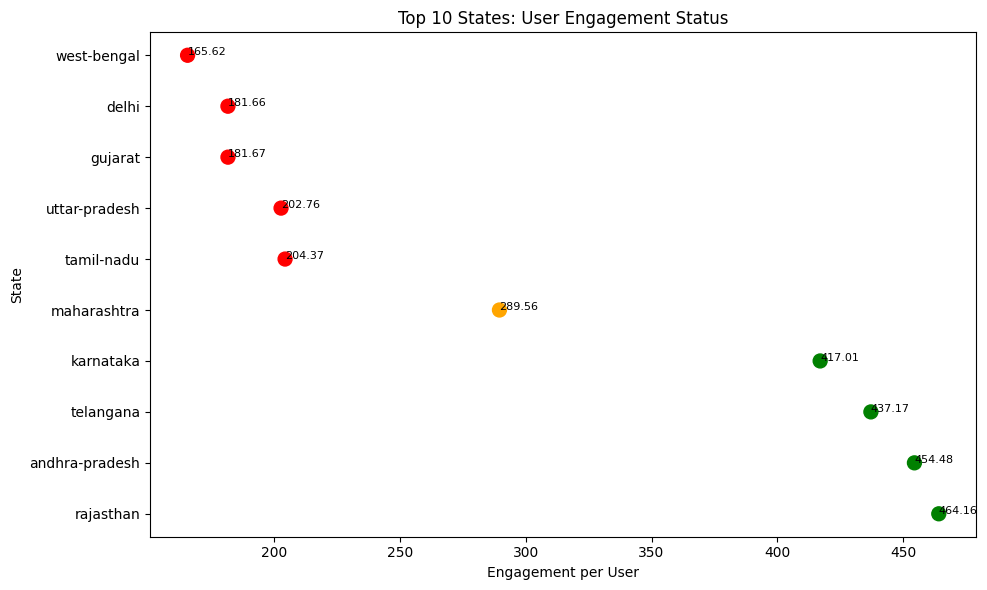

In [1]:
import pandas as pd
import matplotlib.pyplot as plt
import mysql.connector

# ------------------ DB CONNECTION ------------------
conn = mysql.connector.connect(
    host="localhost",
    user="root",
    password="12345678",
    database="phonepe_db"
)

# ------------------ QUERY ------------------
query = """
WITH user_data AS (
    SELECT 
        State,
        SUM(Registered_users) AS Total_Users
    FROM top_user
    GROUP BY State
),

engagement_data AS (
    SELECT 
        State,
        SUM(App_opens) AS Total_App_Opens,
        ROUND(
            SUM(App_opens) * 1.0 / NULLIF(SUM(Registered_users), 0),
        4) AS Engagement_Per_User
    FROM aggregated_user
    GROUP BY State
),

combined AS (
    SELECT 
        u.State,
        u.Total_Users,
        e.Total_App_Opens,
        e.Engagement_Per_User
    FROM user_data u
    JOIN engagement_data e 
        ON u.State = e.State
),

avg_engagement AS (
    SELECT AVG(Engagement_Per_User) AS avg_eng
    FROM combined
),

ranked AS (
    SELECT 
        c.*,
        a.avg_eng,
        RANK() OVER (ORDER BY Total_Users DESC) AS user_rank
    FROM combined c
    CROSS JOIN avg_engagement a
)

SELECT 
    State,
    Total_Users,
    Total_App_Opens,
    Engagement_Per_User,

    CASE 
        WHEN Engagement_Per_User >= avg_eng * 1.2 THEN 'High'
        WHEN Engagement_Per_User >= avg_eng * 0.8 THEN 'Medium'
        ELSE 'Low'
    END AS Engagement_Status

FROM ranked
WHERE user_rank <= 10
ORDER BY Engagement_Per_User DESC;
"""

df = pd.read_sql(query, conn)

# ------------------ COLOR MAPPING ------------------
color_map = {
    "High": "green",
    "Medium": "orange",
    "Low": "red"
}

colors = df["Engagement_Status"].map(color_map)

# ------------------ PLOT ------------------
plt.figure(figsize=(10, 6))

plt.scatter(
    df["Engagement_Per_User"],
    df["State"],
    c=colors,
    s=100
)

# Labels
for i in range(len(df)):
    plt.text(
        df["Engagement_Per_User"].iloc[i] + 0.001,
        df["State"].iloc[i],
        f"{df['Engagement_Per_User'].iloc[i]:.2f}",
        fontsize=8
    )

plt.title("Top 10 States: User Engagement Status")
plt.xlabel("Engagement per User")
plt.ylabel("State")

plt.tight_layout()
plt.show()